In [1]:
import sys
from pathlib import Path
import pickle

import cv2 as cv
import numpy as np
import open3d as o3d

ROOT_DIR = next(
    directory
    for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / "src").is_dir() and (directory / "data").is_dir()
)
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))
CALIBRATION_DIR = ROOT_DIR / "data/calibration_results"
PROCESSED_DIR = ROOT_DIR / "data/processed"
REPORT_IMAGES_DIR = ROOT_DIR / "report/report_images"

from src.reconstruction import (
    create_stereo_matcher,
    compute_disparities,
    merge_global_point_cloud,
    build_local_point_cloud,
    create_charuco_detector,
    estimate_global_pose,
)
from src.calibration_rectification import rectify_image_pair
from src.utils.utils import indexed_images, get_image_at_index
from src.utils.prints import print_matrix
from src.utils.plotting import (
    show_disparity,
    show_geometries,
    save_open3d_screenshot,
)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


# 1. Stereo Matching

In [2]:
# Mapas exportados por el notebook 01.
dataset_name = "palacio"
dataset_dir = ROOT_DIR / "data/raw" / dataset_name
dataset_output_dir = PROCESSED_DIR / dataset_name
disparity_dir = dataset_output_dir / "disparity"
disparity_dir.mkdir(parents=True, exist_ok=True)

with (CALIBRATION_DIR / "stereo_maps.pkl").open("rb") as stream:
    maps = pickle.load(stream)
left_rectification_map_x = np.asarray(maps["left_map_x"])
left_rectification_map_y = np.asarray(maps["left_map_y"])
right_rectification_map_x = np.asarray(maps["right_map_x"])
right_rectification_map_y = np.asarray(maps["right_map_y"])

/var/folders/rj/zqrkpxhx1gvgx0llxc3bts9h0000gn/T/ipykernel_79567/489683009.py:9: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  maps = pickle.load(stream)


In [3]:
left_by_index = indexed_images(dataset_dir, "left")
right_by_index = indexed_images(dataset_dir, "right")
pair_ids = sorted(left_by_index)
images_left = [str(left_by_index[index]) for index in pair_ids]
images_right = [str(right_by_index[index]) for index in pair_ids]

[OK] disp_0: 53.4% de píxeles válidos (WLS=sí)
[OK] disp_1: 53.4% de píxeles válidos (WLS=sí)
[OK] disp_2: 55.7% de píxeles válidos (WLS=sí)
[OK] disp_3: 58.4% de píxeles válidos (WLS=sí)
[OK] disp_4: 59.0% de píxeles válidos (WLS=sí)
[OK] disp_5: 58.6% de píxeles válidos (WLS=sí)
[OK] disp_6: 55.3% de píxeles válidos (WLS=sí)
[OK] disp_7: 57.4% de píxeles válidos (WLS=sí)
[OK] disp_8: 57.9% de píxeles válidos (WLS=sí)
[OK] disp_9: 55.7% de píxeles válidos (WLS=sí)
[OK] disp_10: 54.4% de píxeles válidos (WLS=sí)
[OK] disp_11: 56.1% de píxeles válidos (WLS=sí)
[OK] disp_12: 58.7% de píxeles válidos (WLS=sí)
[OK] disp_13: 59.0% de píxeles válidos (WLS=sí)
[OK] disp_14: 57.1% de píxeles válidos (WLS=sí)
[OK] disp_15: 53.0% de píxeles válidos (WLS=sí)
[OK] disp_16: 53.0% de píxeles válidos (WLS=sí)
[OK] disp_17: 56.8% de píxeles válidos (WLS=sí)
[OK] disp_18: 48.3% de píxeles válidos (WLS=sí)
[OK] disp_19: 46.5% de píxeles válidos (WLS=sí)
[OK] disp_20: 50.3% de píxeles válidos (WLS=sí)
[O

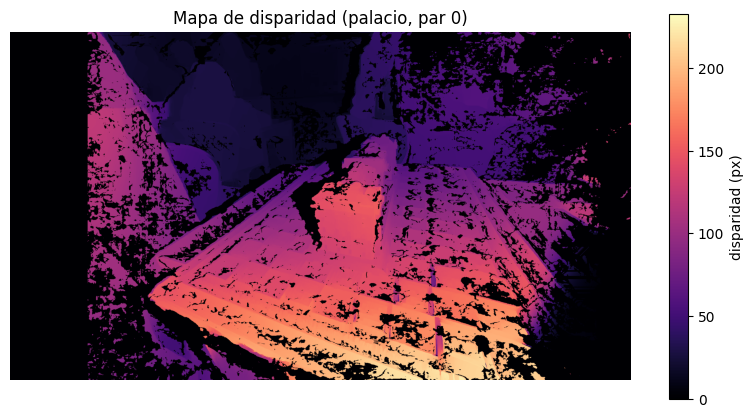

In [4]:
block_size = 11
min_disparity, num_disparities = 0, 240
stereo = create_stereo_matcher(
    min_disparity=min_disparity,
    num_disparities=num_disparities,
    block_size=block_size,
)
compute_disparities(
    images_left,
    images_right,
    stereo,
    left_rectification_map_x,
    left_rectification_map_y,
    right_rectification_map_x,
    right_rectification_map_y,
    str(disparity_dir),
    use_wls=True,
    lr_max_diff=1.5,
    min_confidence=0.0,
)
print(
    f"Disparidades guardadas en {disparity_dir.relative_to(PROCESSED_DIR)} ({len(pair_ids)} pares)"
)

disparity_example = np.load(disparity_dir / "disp_0.npy")
show_disparity(
    disparity_example,
    title=f"Mapa de disparidad ({dataset_name}, par 0)",
    save_path=REPORT_IMAGES_DIR / f"disparidad_{dataset_name}.png",
)

# 2. Computar Nube local

In [5]:
Q = np.asarray(maps["Q"])
Z_MIN, Z_MAX = 100.0, 2000.0

disparity_0 = np.load(disparity_dir / "disp_0.npy")
point_cloud_0 = build_local_point_cloud(
    str(left_by_index[0]),
    disparity_0,
    Q,
    left_rectification_map_x,
    left_rectification_map_y,
    min_disparity=min_disparity,
    z_min=Z_MIN,
    z_max=Z_MAX,
)
print(f"Nube local del par 0: {len(point_cloud_0.points):,} puntos")
show_geometries([point_cloud_0], title=f"Nube local - par 0 ({dataset_name})")

Nube local del par 0: 965,512 puntos


# 3. Pose global

In [6]:
rectified_intrinsic = np.asarray(maps["P1"])[:3, :3]
charuco_board, charuco_detector = create_charuco_detector()

img_left, img_right = get_image_at_index(dataset_name=dataset_name, index=0)
rect_left, _ = rectify_image_pair(img_left, img_right, maps)
camera_to_world_transform_0 = estimate_global_pose(
    cv.cvtColor(rect_left, cv.COLOR_BGR2GRAY),
    charuco_detector,
    charuco_board,
    rectified_intrinsic,
)
if camera_to_world_transform_0 is None:
    print("No se detectó el tablero en el par 0.")
else:
    print_matrix(
        "Pose del par 0 (cámara rectificada → mundo)", camera_to_world_transform_0
    )
    print(
        f"Posición de la cámara en el mundo: {np.round(camera_to_world_transform_0[:3, 3], 1)} mm"
    )

0.923081,0.122326,-0.364634,244.372
-0.382211,0.397395,-0.834261,688.598
0.0428515,0.909458,0.413582,-217.487
0,0,0,1


Posición de la cámara en el mundo: [ 244.4  688.6 -217.5] mm


# 4. Transformación

In [ ]:
global_point_cloud, camera_frames, merged_pair_count, discarded_pair_count = (
    merge_global_point_cloud(
        images_left,
        str(disparity_dir),
        Q,
        left_rectification_map_x,
        left_rectification_map_y,
        charuco_detector,
        charuco_board,
        rectified_intrinsic,
        min_disparity=min_disparity,
        z_min=Z_MIN,
        z_max=Z_MAX,
        voxel_size=2.0,  # Tamaño del vóxel en mm
        merge_every=1,   # Reducir la nube global en cada iteración
        # ROI desactivada por ahora
        roi_min=None,
        roi_max=None,
    )
)

print(
    f"Pares fusionados: {merged_pair_count} | "
    f"descartados sin tablero: {discarded_pair_count}"
)
print(f"Puntos en la nube global: {len(global_point_cloud.points):,}")

global_point_cloud_path = dataset_output_dir / f"nube_global_{dataset_name}.ply"
if not o3d.io.write_point_cloud(
    str(global_point_cloud_path), global_point_cloud
):
    raise OSError(f"No se pudo guardar {global_point_cloud_path}")

print("Nube global guardada en", global_point_cloud_path)

world_origin = o3d.geometry.TriangleMesh.create_coordinate_frame(size=100)
scene_geometries = [global_point_cloud, world_origin, *camera_frames]

save_open3d_screenshot(
    scene_geometries, str(REPORT_IMAGES_DIR / f"poses_{dataset_name}.png")
)
show_geometries(
    scene_geometries,
    title=f"Nube global en el marco de mundo ({dataset_name})",
)


[1] disp_0: 323,982 puntos locales; 323,982 puntos globales
[2] disp_1: 305,079 puntos locales; 557,462 puntos globales
[3] disp_2: 325,097 puntos locales; 748,552 puntos globales
[4] disp_3: 340,487 puntos locales; 989,210 puntos globales
[5] disp_4: 367,451 puntos locales; 1,251,533 puntos globales
[6] disp_5: 381,985 puntos locales; 1,543,028 puntos globales
[7] disp_6: 351,243 puntos locales; 1,746,048 puntos globales
[8] disp_7: 414,353 puntos locales; 2,088,155 puntos globales
[9] disp_9: 392,393 puntos locales; 2,401,413 puntos globales
[10] disp_10: 393,927 puntos locales; 2,730,083 puntos globales
[11] disp_11: 377,136 puntos locales; 3,017,314 puntos globales
[12] disp_12: 366,339 puntos locales; 3,129,083 puntos globales
[13] disp_13: 350,739 puntos locales; 3,306,712 puntos globales
[14] disp_14: 372,309 puntos locales; 3,571,044 puntos globales
[15] disp_15: 397,039 puntos locales; 3,857,110 puntos globales
[16] disp_16: 357,038 puntos locales; 4,120,059 puntos globales
[1

: 